# RQ3 Analysis: CodeBERT Semantic Similarity (Description ↔ Code Diff)

Measures how semantically aligned each PR description (human or AI-generated) is with its actual code diff using **CodeBERT**.

- Uses `microsoft/codebert-base` (bimodal pre-trained model for NL↔PL tasks).
- Extracts `[CLS]` token embeddings (ESE research standard for sequence-level representation).
- Computes **cosine similarity** between description embedding and diff embedding.
- Both human and AI descriptions are compared against the **same** code diff per PR, producing directly comparable scores.
- Diff embeddings are pre-computed once per PR (n=308) and cached for efficiency.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, kruskal
import paired_stats as PS  # Tier-A shared helpers: paired Wilcoxon, FDR, effect sizes
import scikit_posthocs as sp
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel
from pathlib import Path
import os
import re

In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Preprocessing: Diff Cleaning

In [3]:
def clean_diff(patch_text: str) -> str:
    """Extract only the changed lines from a unified diff patch.
    
    - Keeps lines starting with '+' or '-' (added/removed code).
    - Removes diff metadata: '@@' hunk headers, '---', '+++', 'diff --git'.
    - Strips the leading '+'/'-' prefix from each line.
    """
    if not isinstance(patch_text, str) or not patch_text.strip():
        return ''
    
    changed_lines = []
    for line in patch_text.splitlines():
        stripped = line.strip()
        # Skip metadata headers
        if stripped.startswith('@@'):
            continue
        if stripped.startswith('---') or stripped.startswith('+++'):
            continue
        if stripped.startswith('diff --git'):
            continue
        # Keep only changed lines (+ or -)
        if stripped.startswith('+') or stripped.startswith('-'):
            # Strip the leading +/- prefix
            changed_lines.append(stripped[1:].strip())
    
    return '\n'.join(changed_lines)


# Sanity check
sample_patch = """@@ -10,7 +10,9 @@ class Example:
 unchanged line
-    old_function()
+    new_function()
+    added_line()
 another unchanged"""

print(f"Input:\n{sample_patch}")
print(f"\nCleaned output:\n{clean_diff(sample_patch)}")

Input:
@@ -10,7 +10,9 @@ class Example:
 unchanged line
-    old_function()
+    new_function()
+    added_line()
 another unchanged

Cleaned output:
old_function()
new_function()
added_line()


## 2. Data Loading & Preparation

In [4]:
CONTEXT_MAPPING = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}

TARGET_MODELS = [
    'meta-llama/llama-3.1-70b-instruct',
    'gpt-5-mini-2025-08-07',
    'Qwen/Qwen2.5-72B-Instruct'
]

# Load detection results (descriptions)
csv_path = Path('..') / 'datasets' / 'temperature_1' / 'run_3_cleaned' / 'detection_results.csv'
df = pd.read_csv(csv_path, usecols=['pr_id', 'entry_type', 'variation', 'model', 'text']).copy()

# Normalize model names
model_aliases = {
    'meta-llama_llama-3.1-70b-instruct': 'meta-llama/llama-3.1-70b-instruct',
    'meta-llama/llama-3.1-70b-instruct': 'meta-llama/llama-3.1-70b-instruct',
    'gpt-5-mini-2025-08-07': 'gpt-5-mini-2025-08-07',
    'Qwen/Qwen2.5-72B-Instruct': 'Qwen/Qwen2.5-72B-Instruct'
}
df['model'] = df['model'].astype(str).str.strip().map(lambda m: model_aliases.get(m, m))

# Load diffs (file-level patches)
diffs_path = Path('..') / 'datasets' / 'selected_prs_with_diffs_and_file_contents.csv'
diffs_df = pd.read_csv(diffs_path, usecols=['id', 'patch'])
diffs_df['normalized_pr_id'] = diffs_df['id'].astype(str).str.strip()

# Aggregate all file patches per PR into one combined diff string
pr_diffs = (
    diffs_df.groupby('normalized_pr_id')['patch']
    .apply(lambda patches: '\n'.join(str(p) for p in patches if pd.notna(p)))
    .to_dict()
)

# Clean each combined diff
pr_clean_diffs = {pr_id: clean_diff(combined) for pr_id, combined in pr_diffs.items()}

print(f'Loaded {len(pr_clean_diffs)} PR diffs')
print(f'Sample cleaned diff length (chars): {len(next(iter(pr_clean_diffs.values())))}')

Loaded 308 PR diffs
Sample cleaned diff length (chars): 2761


In [5]:
# Split into human and AI subsets (same as lexical density notebook)
ai_df = df[(df['entry_type'] == 'ai') & (df['model'].isin(TARGET_MODELS))].copy()
ai_df = ai_df[ai_df['variation'].isin(CONTEXT_MAPPING.keys())].copy()
ai_df['context_level'] = ai_df['variation']
ai_df['Context_Name'] = ai_df['variation'].map(CONTEXT_MAPPING)
ai_df['normalized_pr_id'] = ai_df['pr_id'].astype(str).str.strip()

human_df = df[df['entry_type'] == 'human'].copy()
human_df['model'] = 'Human'
human_df['context_level'] = 'Original'
human_df['Context_Name'] = 'Original'
human_df['normalized_pr_id'] = human_df['pr_id'].astype(str).str.strip()

# Filter to paired PRs only
valid_ids = set(ai_df['normalized_pr_id']).intersection(set(human_df['normalized_pr_id']))
# Also filter to PRs that have diffs available
valid_ids = valid_ids.intersection(set(pr_clean_diffs.keys()))
# Exclude PRs with empty cleaned diffs
valid_ids = {pid for pid in valid_ids if pr_clean_diffs.get(pid, '').strip()}

ai_df = ai_df[ai_df['normalized_pr_id'].isin(valid_ids)].copy()
human_df = human_df[human_df['normalized_pr_id'].isin(valid_ids)].copy()

print(f'Data source: {csv_path}')
print(f'Paired PR count (with diffs): {len(valid_ids)}')
print('Models found:', sorted(ai_df['model'].unique().tolist()))
print('Contexts found:', sorted(ai_df['variation'].unique().tolist()))
print(f'Human rows: {len(human_df)}, AI rows: {len(ai_df)}')

Data source: ../datasets/temperature_1/run_3_cleaned/detection_results.csv
Paired PR count (with diffs): 308
Models found: ['Qwen/Qwen2.5-72B-Instruct', 'gpt-5-mini-2025-08-07', 'meta-llama/llama-3.1-70b-instruct']
Contexts found: ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
Human rows: 308, AI rows: 5526


## 3. CodeBERT Embedding & Similarity Computation

Strategy for efficiency:
1. Pre-compute diff embeddings once for each PR (n≈308) — cached in a dict.
2. Process descriptions in chunks (like the BERTScore notebook).
3. Use `[CLS]` token from last hidden state as the sequence-level semantic vector.

In [6]:
# Allow MPS to use more memory
os.environ['PYTORCH_MPS_HIGH_WATERMARK_RATIO'] = '0.0'

# Detect best available device
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')
print(f'Using device: {device}')

# Load CodeBERT model and tokenizer
MODEL_NAME = 'microsoft/codebert-base'
MAX_LENGTH = 512

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device)
model.eval()

print(f'Loaded {MODEL_NAME} (max_length={MAX_LENGTH})')

Using device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loaded microsoft/codebert-base (max_length=512)


In [7]:
def get_cls_embeddings_batch(texts: list[str], tokenizer, model, device, max_length=512) -> torch.Tensor:
    """Compute [CLS] token embeddings for a batch of texts.
    
    Returns a tensor of shape (batch_size, hidden_dim).
    """
    # Replace empty strings with a single space to avoid tokenizer issues
    texts = [t if t and t.strip() else ' ' for t in texts]

    encoded = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors='pt'
    ).to(device)
    
    with torch.no_grad():
        outputs = model(**encoded)
    
    # [CLS] is the first token (index 0)
    cls_embeddings = outputs.last_hidden_state[:, 0, :]
    return cls_embeddings

In [8]:
# Pre-compute diff embeddings (one per PR, n≈308)
BATCH_SIZE = 16

unique_pr_ids = sorted(valid_ids)
diff_texts = [pr_clean_diffs[pid] for pid in unique_pr_ids]

print(f'Pre-computing diff embeddings for {len(unique_pr_ids)} PRs (batch_size={BATCH_SIZE})...')

diff_embeddings_list = []
for start in range(0, len(diff_texts), BATCH_SIZE):
    end = min(start + BATCH_SIZE, len(diff_texts))
    batch = diff_texts[start:end]
    embs = get_cls_embeddings_batch(batch, tokenizer, model, device, MAX_LENGTH)
    diff_embeddings_list.append(embs.cpu())

    if device.type == 'mps':
        torch.mps.empty_cache()
    elif device.type == 'cuda':
        torch.cuda.empty_cache()

diff_embeddings_tensor = torch.cat(diff_embeddings_list, dim=0)  # (n_prs, hidden_dim)

# Build lookup: pr_id -> embedding tensor (1, hidden_dim)
diff_embedding_map = {
    pid: diff_embeddings_tensor[i].unsqueeze(0)
    for i, pid in enumerate(unique_pr_ids)
}

print(f'Diff embeddings computed. Shape per PR: {diff_embeddings_tensor.shape[1]}-dim')

Pre-computing diff embeddings for 308 PRs (batch_size=16)...


Diff embeddings computed. Shape per PR: 768-dim


In [9]:
# Compute similarity for ALL descriptions (human + AI) in chunked batches
combined_df = pd.concat([human_df, ai_df], ignore_index=True)

CHUNK_SIZE = 64
total = len(combined_df)
all_similarities = []

print(f'Processing {total} descriptions in chunks of {CHUNK_SIZE} (batch_size={BATCH_SIZE})...')

for start_idx in range(0, total, CHUNK_SIZE):
    end_idx = min(start_idx + CHUNK_SIZE, total)
    chunk = combined_df.iloc[start_idx:end_idx]
    
    # Get description texts
    desc_texts = [str(t) if pd.notna(t) else '' for t in chunk['text'].values]
    pr_ids = chunk['normalized_pr_id'].values
    
    # Compute description embeddings in sub-batches
    desc_embs_list = []
    for b_start in range(0, len(desc_texts), BATCH_SIZE):
        b_end = min(b_start + BATCH_SIZE, len(desc_texts))
        batch_texts = desc_texts[b_start:b_end]
        embs = get_cls_embeddings_batch(batch_texts, tokenizer, model, device, MAX_LENGTH)
        desc_embs_list.append(embs.cpu())
    
    desc_embs = torch.cat(desc_embs_list, dim=0)  # (chunk_size, hidden_dim)
    
    # Look up cached diff embeddings and compute cosine similarity
    for i in range(len(chunk)):
        pid = pr_ids[i]
        diff_emb = diff_embedding_map.get(pid)
        if diff_emb is not None:
            sim = F.cosine_similarity(desc_embs[i].unsqueeze(0), diff_emb, dim=1).item()
        else:
            sim = np.nan
        all_similarities.append(sim)
    
    # Free memory
    if device.type == 'mps':
        torch.mps.empty_cache()
    elif device.type == 'cuda':
        torch.cuda.empty_cache()
    
    print(f'  Processed {end_idx}/{total} ({end_idx * 100 // total}%)')

combined_df['codebert_similarity'] = all_similarities

# Split back
human_df = combined_df[combined_df['model'] == 'Human'].copy()
ai_df = combined_df[combined_df['model'] != 'Human'].copy()

print(f'\nCodeBERT similarity computation complete.')
print(f'Score range: [{combined_df["codebert_similarity"].min():.4f}, {combined_df["codebert_similarity"].max():.4f}]')
print(f'Human mean: {human_df["codebert_similarity"].mean():.4f}, AI mean: {ai_df["codebert_similarity"].mean():.4f}')

Processing 5834 descriptions in chunks of 64 (batch_size=16)...


  Processed 64/5834 (1%)


  Processed 128/5834 (2%)


  Processed 192/5834 (3%)


  Processed 256/5834 (4%)


  Processed 320/5834 (5%)


... (82 outputs left out)

  Processed 5632/5834 (96%)


  Processed 5696/5834 (97%)


  Processed 5760/5834 (98%)


  Processed 5824/5834 (99%)
  Processed 5834/5834 (100%)

CodeBERT similarity computation complete.
Score range: [0.8515, 0.9978]
Human mean: 0.9776, AI mean: 0.9643


In [10]:
print('CodeBERT similarity metrics computed.')
print(f'Human entries: {len(human_df)}, AI entries: {len(ai_df)}')
display(combined_df[['entry_type', 'model', 'normalized_pr_id', 'codebert_similarity']].head(10))

CodeBERT similarity metrics computed.
Human entries: 308, AI entries: 5526


,entry_type,model,normalized_pr_id,codebert_similarity
0,human,Human,PR_kwDOAQ0TF847_vbu,0.990071
1,human,Human,MDExOlB1bGxSZXF1ZXN0Nzc2MTUxNDk=,0.956498
2,human,Human,PR_kwDOAQ0TF84shSgK,0.993511
3,human,Human,MDExOlB1bGxSZXF1ZXN0MjY4MTEzNzYz,0.983620
4,human,Human,MDExOlB1bGxSZXF1ZXN0MTEyNDQ1MjQ0,0.962484
5,human,Human,PR_kwDOAQ0TF842CEhF,0.992535
6,human,Human,PR_kwDOAQ0TF85CKVyy,0.992394
7,human,Human,MDExOlB1bGxSZXF1ZXN0MTE3NDg1ODY3,0.965889
8,human,Human,MDExOlB1bGxSZXF1ZXN0MTYwNDk0NTcy,0.984022
9,human,Human,MDExOlB1bGxSZXF1ZXN0MTAyOTIyNDMx,0.979581


## 3.1 CodeBERT Similarity Boxplots by Context per LLM (with Human Baseline)

This mirrors the reading-ease setup:

- One panel per LLM model (stacked vertically).
- Each panel includes the 6 AI context boxplots.
- A Human baseline boxplot is included in each panel for direct comparison.

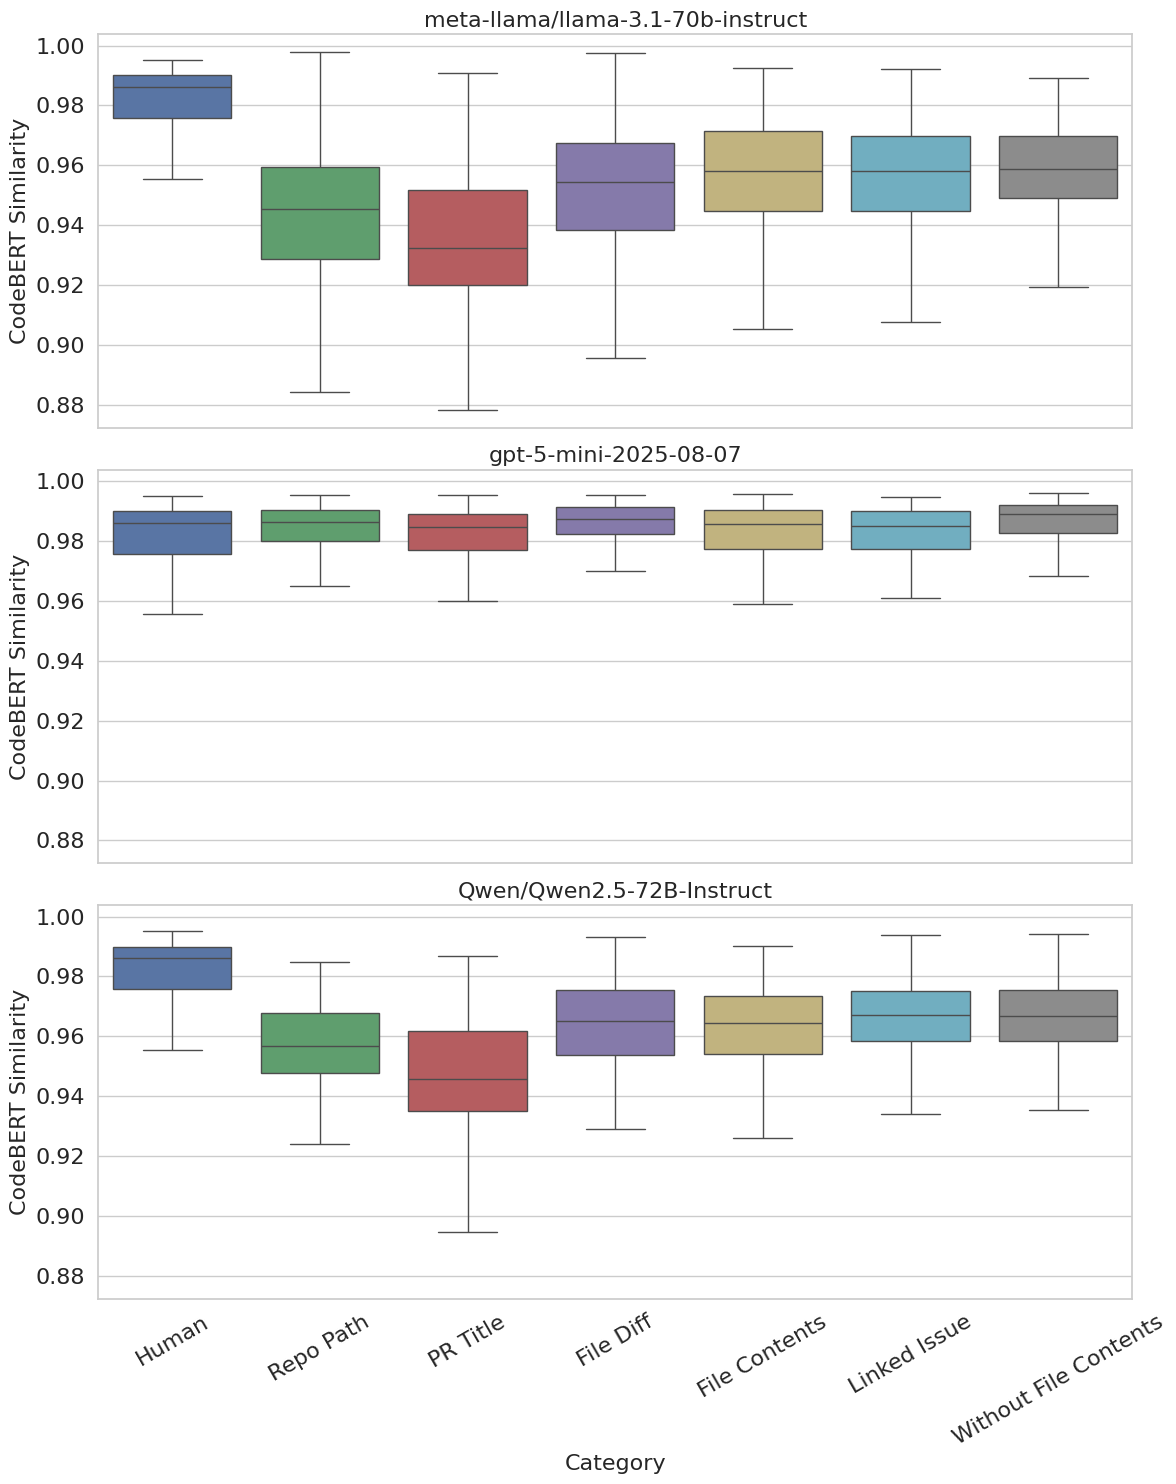

In [11]:
context_order = [
    'Repo Path', 'PR Title', 'File Diff',
    'File Contents', 'Linked Issue', 'Without File Contents'
 ]
llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=16)

    ai_slice = ai_df[ai_df['model'] == model][['codebert_similarity', 'Context_Name']].copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['codebert_similarity']].copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['codebert_similarity', 'Category']],
        ai_slice[['codebert_similarity', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='codebert_similarity',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=16)
    ax.set_ylabel('CodeBERT Similarity', fontsize=16)
    ax.tick_params(axis='x', rotation=30, labelsize=16)
    ax.tick_params(axis='y', labelsize=16)

plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'codebert.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 4. Descriptive Statistics

In [12]:
print('Overall descriptive stats (CodeBERT Similarity):\n')
for label, sub_df in [('Human', human_df)] + [(m, ai_df[ai_df['model'] == m]) for m in TARGET_MODELS]:
    vals = sub_df['codebert_similarity'].dropna()
    print(f'{label}: N={len(vals)}, Mean={vals.mean():.4f}, Median={vals.median():.4f}, '
          f'Std={vals.std():.4f}, Min={vals.min():.4f}, Max={vals.max():.4f}')

Overall descriptive stats (CodeBERT Similarity):

Human: N=308, Mean=0.9776, Median=0.9861, Std=0.0222, Min=0.8515, Max=0.9951
meta-llama/llama-3.1-70b-instruct: N=1842, Mean=0.9504, Median=0.9528, Std=0.0226, Min=0.8784, Max=0.9978
gpt-5-mini-2025-08-07: N=1842, Mean=0.9817, Median=0.9863, Std=0.0152, Min=0.8606, Max=0.9961
Qwen/Qwen2.5-72B-Instruct: N=1842, Mean=0.9608, Median=0.9626, Std=0.0157, Min=0.8947, Max=0.9941


## 5. Statistical Testing & Effect Size

In [13]:
# Per-model OVERALL comparison (PAIRED, per-PR mean across contexts) -- Tier-A.
# Replaces independent-samples Mann-Whitney U on paired human/AI data. For each model,
# summarise its six-context output per PR as the mean, then pair against the human value
# for the same PR (Wilcoxon signed-rank). Effect sizes: Cliff's delta (dominance) +
# matched-pairs rank-biserial. FDR (BH) applied within each metric. See paired_stats.py.
models = ai_df['model'].unique()
model_results = []
for _col, _label in [('codebert_similarity', 'CodeBERT Similarity')]:
    _ai_all = ai_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _hu_all = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
    _m = pd.concat([_hu_all.rename('h'), _ai_all.rename('a')], axis=1, join='inner').dropna()
    _r = PS.paired_test(_m['h'].values, _m['a'].values)
    print("[%s] pooled Human vs AI (paired): n=%d, Wilcoxon p=%.3g, Cliff's d=%.4f (%s)"
          % (_label, _r['n'], _r['p'], _r['cliffs_delta'], _r['magnitude']))
    for _model in ai_df['model'].unique():
        _ai_pr = ai_df[ai_df['model'] == _model].dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _hu_pr = human_df.dropna(subset=[_col]).groupby('normalized_pr_id')[_col].mean()
        _merged = pd.concat([_hu_pr.rename('h'), _ai_pr.rename('a')], axis=1, join='inner').dropna()
        _r = PS.paired_test(_merged['h'].values, _merged['a'].values)
        model_results.append({
            'Model': _model, 'Metric': _label, 'N pairs': _r['n'],
            'Human Median': _r['median_human'], 'Model Median': _r['median_ai'],
            'Wilcoxon p': _r['p'], "Cliff's Delta": round(_r['cliffs_delta'], 4),
            'Rank-Biserial': round(_r['rank_biserial'], 4), 'Effect Size': _r['magnitude'],
        })
model_results_df = pd.DataFrame(model_results)
model_results_df = PS.apply_fdr_by(model_results_df, 'Metric', pcol='Wilcoxon p')
model_results_df['Sig'] = model_results_df['adj_Wilcoxon p'].apply(PS.sig_mark)
display(model_results_df)


[CodeBERT Similarity] pooled Human vs AI (paired): n=308, Wilcoxon p=4.76e-25, Cliff's d=0.6566 (Large)


,Model,Metric,N pairs,Human Median,Model Median,Wilcoxon p,Cliff's Delta,Rank-Biserial,Effect Size,adj_Wilcoxon p,sig,Sig
0,meta-llama/llama-3.1-70b-instruct,CodeBERT Similarity,308,0.986101,0.948206,7.195397e-34,0.7455,0.7975,Large,2.158619e-33,True,***
1,gpt-5-mini-2025-08-07,CodeBERT Similarity,308,0.986101,0.985868,7.429391e-01,-0.0046,0.0216,Negligible,7.429391e-01,False,n.s.
2,Qwen/Qwen2.5-72B-Instruct,CodeBERT Similarity,308,0.986101,0.960874,2.102251e-27,0.6869,0.7130,Large,3.153376e-27,True,***


## 6. Human vs AI Context Variations (Cliff's δ per Model)

In [14]:
# Human vs. AI per context (PAIRED): Cliff's delta + Wilcoxon signed-rank, BH-FDR -- Tier-A.
# Filter by the stable variation code (P-1..P-6); display labels differ across notebooks
# ('File Diff' vs 'PR Diffs', 'Linked Issue' vs 'Related Issues'), so the code is the safe key.
import os as _os
VARIATION_TO_CTX = {'P-1': 'Repo Path', 'P-2': 'PR Title', 'P-3': 'File Diff', 'P-4': 'File Contents', 'P-5': 'Linked Issue', 'P-6': 'Without File Contents'}
variation_codes = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
variation_names = [VARIATION_TO_CTX[_p] for _p in variation_codes]
_long = []
for _col, _label in [('codebert_similarity', 'CodeBERT Similarity')]:
    for _model in ai_df['model'].unique():
        for _pcode in variation_codes:
            _slice = ai_df[(ai_df['model'] == _model) & (ai_df['variation'] == _pcode)]
            _r = PS.paired_test_from_frames(human_df, _slice, _col, key='normalized_pr_id')
            _long.append({'Metric': _label, 'Model': _model, 'Context': VARIATION_TO_CTX[_pcode],
                          'n': _r['n'], 'cliffs_delta': _r['cliffs_delta'], 'magnitude': _r['magnitude'],
                          'rank_biserial': _r['rank_biserial'], 'p': _r['p']})
long_df = PS.apply_fdr_by(pd.DataFrame(_long), 'Metric', pcol='p')
long_df['Sig'] = long_df['adj_p'].apply(PS.sig_mark)
_os.makedirs('outputs', exist_ok=True)
long_df.to_csv('outputs/rq3_codebert_paired_stats.csv', index=False)
print('Saved tidy paired stats -> outputs/rq3_codebert_paired_stats.csv')

def _fmt_cell(x):
    return "%.3f (%s) %s" % (x['cliffs_delta'], x['magnitude'][0], x['Sig'])
context_tables = {}
for _col, _label in [('codebert_similarity', 'CodeBERT Similarity')]:
    _sub = long_df[long_df['Metric'] == _label].copy()
    _sub['cell'] = _sub.apply(_fmt_cell, axis=1)
    _piv = _sub.pivot(index='Model', columns='Context', values='cell').reindex(columns=variation_names)
    context_tables[_label] = _piv
    print("\n=== %s: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===" % _label)
    display(_piv)
result_df = list(context_tables.values())[-1]
effect_df = list(context_tables.values())[-1]


Saved tidy paired stats -> outputs/rq3_codebert_paired_stats.csv

=== CodeBERT Similarity: Human vs AI per context -- Cliff's delta (paired Wilcoxon, BH-FDR) ===


Context,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
Qwen/Qwen2.5-72B-Instruct,0.705 (L) ***,0.767 (L) ***,0.623 (L) ***,0.616 (L) ***,0.586 (L) ***,0.581 (L) ***
gpt-5-mini-2025-08-07,-0.050 (N) n.s.,0.067 (N) **,-0.185 (S) ***,-0.010 (N) n.s.,0.031 (N) n.s.,-0.229 (S) ***
meta-llama/llama-3.1-70b-instruct,0.740 (L) ***,0.788 (L) ***,0.672 (L) ***,0.685 (L) ***,0.675 (L) ***,0.690 (L) ***


## 7. Summary Table & Export

In [15]:
summary_rows = []
for model_name in ['Human'] + TARGET_MODELS:
    vals = combined_df[combined_df['model'] == model_name]['codebert_similarity'].dropna()
    summary_rows.append({
        'Model': model_name,
        'Metric': 'CodeBERT Similarity',
        'N': len(vals),
        'Mean': round(vals.mean(), 4),
        'Median': round(vals.median(), 4),
        'Std': round(vals.std(), 4),
        'Min': round(vals.min(), 4),
        'Max': round(vals.max(), 4),
        'Q1': round(vals.quantile(0.25), 4),
        'Q3': round(vals.quantile(0.75), 4)
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

out_dir = Path('outputs')
out_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(out_dir / 'rq3_codebert_summary.csv', index=False)
effect_df.reset_index().to_csv(out_dir / 'rq3_codebert_cliffs_delta_by_context.csv', index=False)
model_results_df.to_csv(out_dir / 'rq3_codebert_human_vs_model_stats.csv', index=False)
print('Saved outputs to outputs/.')
print('- rq3_codebert_summary.csv')
print('- rq3_codebert_cliffs_delta_by_context.csv')
print('- rq3_codebert_human_vs_model_stats.csv')

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,CodeBERT Similarity,308,0.9776,0.9861,0.0222,0.8515,0.9951,0.9758,0.9900
1,meta-llama/llama-3.1-70b-instruct,CodeBERT Similarity,1842,0.9504,0.9528,0.0226,0.8784,0.9978,0.9357,0.9668
2,gpt-5-mini-2025-08-07,CodeBERT Similarity,1842,0.9817,0.9863,0.0152,0.8606,0.9961,0.9797,0.9904
3,Qwen/Qwen2.5-72B-Instruct,CodeBERT Similarity,1842,0.9608,0.9626,0.0157,0.8947,0.9941,0.9505,0.9731


Saved outputs to outputs/.
- rq3_codebert_summary.csv
- rq3_codebert_cliffs_delta_by_context.csv
- rq3_codebert_human_vs_model_stats.csv
